# Proyecto de Aplicacion Time Series

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from datetime import date
import holidays
import plotly.graph_objs as go
from plotly.offline import iplot
import plotly.offline as pyo
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, MaxAbsScaler, RobustScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

## Visualización de datos

In [2]:
df = pd.read_csv('gripe.csv')
df.head()

,Unnamed: 0,Id,week,region_code,region_name,TauxGrippe
0,0,3239,2014-01-05,26,BOURGOGNE,0.0
1,1,3261,2013-12-29,26,BOURGOGNE,0.0
2,2,3283,2013-12-22,26,BOURGOGNE,0.0
3,3,3305,2013-12-15,26,BOURGOGNE,0.0
4,4,3327,2013-12-08,26,BOURGOGNE,4.0


In [3]:
def plot_dataset(df, title):
    data = []

    value = go.Scatter(
        x=df.index,
        y=df.value,
        mode="lines",
        name="values",
        marker=dict(),
        text=df.index,
        line=dict(color="rgba(0,0,0, 0.3)"),
    )
    data.append(value)

    layout = dict(
        title=title,
        xaxis=dict(title="Date", ticklen=5, zeroline=False),
        yaxis=dict(title="Value", ticklen=5, zeroline=False),
    )

    fig = dict(data=data, layout=layout)
    iplot(fig)

In [5]:
# Usamos la fecha como índice temporal
df = df.set_index(['week'])

# Renombramos la variable objetivo
df = df.rename(columns={'TauxGrippe': 'value'})

# Convertimos el índice a formato fecha
df.index = pd.to_datetime(df.index)

# Ordenamos cronológicamente la serie temporal
if not df.index.is_monotonic_increasing:
    df = df.sort_index()

# Visualización inicial de la serie temporal
plot_dataset(df, title='Tasa de gripe semanal')

El gráfico muestra la evolución temporal de la tasa semanal de gripe entre 2004 y 2014. Se observan picos muy pronunciados en determinados periodos del año, reflejando episodios epidémicos y un comportamiento claramente estacional. Además, la serie presenta largos intervalos con valores bajos y aumentos bruscos en momentos concretos, lo que indica una elevada variabilidad temporal

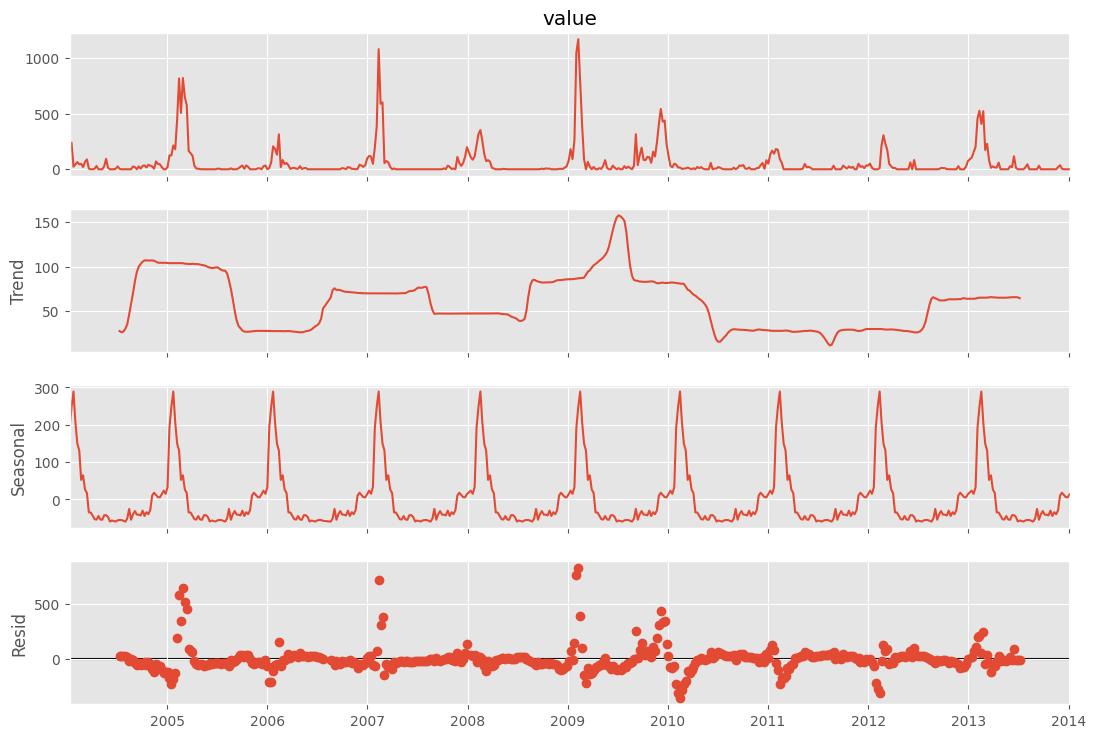

In [27]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Eliminamos valores faltantes
serie = df['value'].dropna()

# Descomposición de la serie temporal
decomposition = seasonal_decompose(
    serie,
    model='additive',
    period=52
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

La descomposición confirma claramente que la serie temporal de gripe presenta una fuerte estacionalidad anual. En la componente estacional se observan picos que se repiten de forma periódica aproximadamente cada año, coincidiendo con los brotes epidémicos de gripe. La tendencia muestra variaciones generales en la intensidad de la enfermedad a lo largo del tiempo, con periodos de mayor y menor incidencia. Por otro lado, la componente residual recoge fluctuaciones irregulares y eventos extremos que no pueden explicarse únicamente mediante la tendencia o la estacionalidad. En conjunto, la descomposición permite concluir que la serie no es completamente estacionaria y que el comportamiento estacional constituye una de sus características más relevantes.

## Preparación de datos

In [6]:
#transformamos la serie temporal en un problema de regresión supervisada
#creamos el vector de time-delay embedding

def create_time_delay_embedding(data, horizon=6, final_lag=24, column="y", column_index=None):
    df = pd.DataFrame()
    df["y"] = data[column].copy()

    for i in range(horizon, final_lag + 1):
        df["lag_{}".format(i)] = data[column].shift(i)

    if column_index is None:
        df.index = data.index
    else:
        df.index = data[column_index]

    return df

In [8]:
# Usamos 52 semanas anteriores (un año) como contexto para predecir la siguiente semana

final_lag = 52
horizon = 1

df_time_delay = create_time_delay_embedding(
    df,
    horizon=horizon,
    final_lag=final_lag,
    column="value"
)

df_time_delay = df_time_delay.dropna()

In [9]:
# Añadimos variables temporales relacionadas con la estacionalidad
df_features = (
    df_time_delay
    .assign(month = df_time_delay.index.month)
    .assign(week_of_year = df_time_delay.index.isocalendar().week.astype(int))
)

df_features.head()

,y,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,lag_45,lag_46,lag_47,lag_48,lag_49,lag_50,lag_51,lag_52,month,week_of_year
week,,,,,,,,,,,,,,,,,,,,,
2005-01-09,125.0,20.0,0.0,0.0,19.0,45.0,48.0,71.0,5.0,25.0,...,20.0,49.0,45.0,65.0,44.0,23.0,237.0,154.0,1,1
2005-01-16,124.0,125.0,20.0,0.0,0.0,19.0,45.0,48.0,71.0,5.0,...,66.0,20.0,49.0,45.0,65.0,44.0,23.0,237.0,1,2
2005-01-23,214.0,124.0,125.0,20.0,0.0,0.0,19.0,45.0,48.0,71.0,...,89.0,66.0,20.0,49.0,45.0,65.0,44.0,23.0,1,3
2005-01-30,180.0,214.0,124.0,125.0,20.0,0.0,0.0,19.0,45.0,48.0,...,6.0,89.0,66.0,20.0,49.0,45.0,65.0,44.0,1,4
2005-02-06,446.0,180.0,214.0,124.0,125.0,20.0,0.0,0.0,19.0,45.0,...,0.0,6.0,89.0,66.0,20.0,49.0,45.0,65.0,2,5


In [10]:
# Dividimos el dataset en entrenamiento, validación y prueba

def feature_label_split(df, target_col):
    y = df[[target_col]]
    X = df.drop(columns=[target_col])
    return X, y


def train_val_test_split(df, target_col, test_ratio):
    val_ratio = test_ratio / (1 - test_ratio)
    X, y = feature_label_split(df, target_col)

    # No se mezclan los datos para respetar el orden temporal
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_ratio, shuffle=False
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=val_ratio, shuffle=False
    )

    return X_train, X_val, X_test, y_train, y_val, y_test


# Función para seleccionar el tipo de escalado
def get_scaler(scaler):
    scalers = {
        "minmax": MinMaxScaler,
        "standard": StandardScaler,
        "maxabs": MaxAbsScaler,
        "robust": RobustScaler,
    }
    return scalers.get(scaler.lower())()


# División temporal del dataset
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(
    df_features,
    'y',
    0.2
)

In [11]:
# Realizamos el escalado de datos

scaler = get_scaler('minmax')

X_train_arr = scaler.fit_transform(X_train)
X_val_arr = scaler.transform(X_val)
X_test_arr = scaler.transform(X_test)

y_train_arr = scaler.fit_transform(y_train)
y_val_arr = scaler.transform(y_val)
y_test_arr = scaler.transform(y_test)

In [12]:
# Número de muestras procesadas en cada iteración
batch_size = 64

# Convertimos los datos a tensores de PyTorch
train_features = torch.Tensor(X_train_arr)
train_targets = torch.Tensor(y_train_arr)

val_features = torch.Tensor(X_val_arr)
val_targets = torch.Tensor(y_val_arr)

test_features = torch.Tensor(X_test_arr)
test_targets = torch.Tensor(y_test_arr)

# Creamos datasets de PyTorch para entrenamiento, validación y prueba
train = TensorDataset(train_features, train_targets)
val = TensorDataset(val_features, val_targets)
test = TensorDataset(test_features, test_targets)

# Creamos DataLoaders para procesar los datos por lotes
train_loader = DataLoader(train, batch_size=batch_size, shuffle=False, drop_last=True)
val_loader = DataLoader(val, batch_size=batch_size, shuffle=False, drop_last=True)
test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, drop_last=True)

# DataLoader para evaluar muestra a muestra
test_loader_one = DataLoader(test, batch_size=1, shuffle=False, drop_last=True)

## Definición y Entrenamiento del Modelo

In [13]:
import torch.nn as nn

#La clase LSTMModel inicia un módulo LSTM basado en la clase nn.Module de PyTorch.
class LSTMModel(nn.Module):

    #El método __init__ que inicia una instancia de LSTM.
    def __init__(self, input_dim, hidden_dim, layer_dim, output_dim, dropout_prob):

        super(LSTMModel, self).__init__()

        # Definiendo el número de capas y los nodos en cada capa
        self.hidden_dim = hidden_dim
        self.layer_dim = layer_dim

        # Capas LSTM
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, layer_dim, batch_first=True, dropout=dropout_prob
        )

        # Capa completamente conectada
        self.fc = nn.Linear(hidden_dim, output_dim)

    #El método forward toma el tensor de entrada x y realiza la propagación hacia adelante
    def forward(self, x):

        # Inicializando el estado oculto para la primera entrada con ceros
        h0 = torch.zeros(self.layer_dim, x.size(0), self.hidden_dim, device=x.device).requires_grad_()
        # Inicializando el estado de celda para la primera entrada con ceros
        c0 = torch.zeros(self.layer_dim, x.size(0), self.hidden_dim, device=x.device).requires_grad_()

        # Necesitamos desvincular porque estamos haciendo retropropagación truncada a través del tiempo (BPTT)
        # Si no lo hacemos, retrocederemos hasta el principio incluso después de pasar por otro batch
        # Propagación hacia adelante pasando la entrada, el estado oculto y el estado de celda al modelo
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))

        # Reorganizando las salidas en la forma de (tamaño del batch, longitud de secuencia, tamaño oculto)
        # para que pueda encajar en la capa completamente conectada
        out = out[:, -1, :]

        # Convertir el estado final a nuestra forma de salida deseada (tamaño del batch, output_dim)
        out = self.fc(out)

        return out


In [14]:
def get_model(model, model_params):
    models = {
        "lstm": LSTMModel,
         }
    return models.get(model.lower())(**model_params)

Se seleccionó una arquitectura LSTM debido a su capacidad para modelar dependencias temporales y patrones estacionales en series secuenciales. En este caso, la tasa semanal de gripe presenta picos epidémicos y comportamientos recurrentes a lo largo del tiempo, por lo que una red LSTM resulta adecuada para aprender la relación entre observaciones pasadas y valores futuros.

In [17]:
#La clase Optimization es una clase auxiliar que permite entrenar, validar y predecir
class Optimization:

    def __init__(self, model, loss_fn, optimizer):

        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.train_losses = []
        self.val_losses = []

    #El método train_step completa un paso de entrenamiento.
    def train_step(self, x, y):

        # Establece el modelo en modo de entrenamiento
        self.model.train()

        # Realiza predicciones
        yhat = self.model(x)

         # Calcula la pérdida
        loss = self.loss_fn(y, yhat)

        # Calcula los gradientes
        loss.backward()

        # Actualiza los parámetros y pone a cero los gradientes
        self.optimizer.step()
        self.optimizer.zero_grad()

        # Devuelve la pérdida
        return loss.item()

    #El método train realiza el entrenamiento del modelo
    def train(self, train_loader, val_loader, batch_size=64, n_epochs=50, n_features=1):


        model_path = f'{self.model}_{datetime.now().strftime("%Y-%m-%d %H:%M:%S")}'

        for epoch in range(1, n_epochs + 1):
            batch_losses = []
            for x_batch, y_batch in train_loader:
                x_batch = x_batch.view([batch_size, -1, n_features])
                y_batch = y_batch
                loss = self.train_step(x_batch, y_batch)
                batch_losses.append(loss)
            training_loss = np.mean(batch_losses)
            self.train_losses.append(training_loss)

            with torch.no_grad():
                batch_val_losses = []
                for x_val, y_val in val_loader:
                    x_val = x_val.view([batch_size, -1, n_features])
                    y_val = y_val
                    self.model.eval()
                    yhat = self.model(x_val)
                    val_loss = self.loss_fn(y_val, yhat).item()
                    batch_val_losses.append(val_loss)
                validation_loss = np.mean(batch_val_losses)
                self.val_losses.append(validation_loss)

            if (epoch <= 10) | (epoch % 50 == 0):
                print(
                    f"[{epoch}/{n_epochs}] Training loss: {training_loss:.4f}\t Validation loss: {validation_loss:.4f}"
                )

        torch.save(self.model.state_dict(), model_path)

    #El método evaluate realiza la evaluación del modelo
    def evaluate(self, test_loader, batch_size=1, n_features=1):

        with torch.no_grad():
            predictions = []
            values = []
            for x_test, y_test in test_loader:
                x_test = x_test.view([batch_size, -1, n_features])
                y_test = y_test
                self.model.eval()
                yhat = self.model(x_test)
                yhat=yhat.cpu().data.numpy()
                predictions.append(yhat)
                y_test=y_test.cpu().data.numpy()
                values.append(y_test)

        return predictions, values

    #El método plot_losses traza los valores de pérdida calculados para entrenamiento y validación
    def plot_losses(self):

        plt.style.use('ggplot')
        plt.figure(figsize=(10,5))
        plt.plot(self.train_losses, label="Training loss")
        plt.plot(self.val_losses, label="Validation loss")
        plt.legend()
        plt.title("Losses")
        plt.show()
        plt.close()

In [18]:
def General_Settings(model_name):

        input_dim = len(X_train.columns)
        output_dim = 1
        hidden_dim = 64
        layer_dim = 3
        batch_size = 64
        dropout = 0.2
        n_epochs = 20
        learning_rate = 1e-3
        weight_decay = 1e-6

        model_params = {'input_dim': input_dim,
                        'hidden_dim' : hidden_dim,
                        'layer_dim' : layer_dim,
                        'output_dim' : output_dim,
                        'dropout_prob' : dropout}
        model = get_model(model_name, model_params)
        loss_fn = nn.MSELoss(reduction="mean")
        optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

        opt = Optimization(model=model, loss_fn=loss_fn, optimizer=optimizer)
        opt.train(train_loader, val_loader, batch_size=batch_size, n_epochs=n_epochs, n_features=input_dim)
        opt.plot_losses()

        predictions, values = opt.evaluate(
            test_loader_one,
            batch_size=1,
            n_features=input_dim
        )
        return predictions,values

Configura los hiperparámetros del modelo LSTM, ejecuta el entrenamiento y validación, representa la curva de pérdidas y realiza la evaluación final sobre el conjunto de prueba.

In [19]:
def inverse_transform(scaler, df, columns):
    for col in columns:
        df[col] = scaler.inverse_transform(df[col])
    return df


def format_predictions(predictions, values, df_test, scaler, col_name="y"):
    vals = np.concatenate(values, axis=0).ravel()
    preds = np.concatenate(predictions, axis=0).ravel()
    df_result = pd.DataFrame(data={col_name: vals, "prediction": preds}, index=df_test.head(len(vals)).index)
    df_result = df_result.sort_index()
    df_result = inverse_transform(scaler, df_result, [[col_name, "prediction"]])
    return df_result

Revierte el escalado aplicado a los datos y organiza las predicciones del modelo junto con los valores reales para facilitar su comparación y análisis.

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Calcula las métricas de evaluación del modelo utilizando MAE, RMSE y R² para medir la precisión de las predicciones sobre la tasa semanal de gripe.

def calculate_metrics(df, col_name="y"):
    result_metrics = {'mae' : mean_absolute_error(df[col_name], df.prediction),
                      'rmse' : mean_squared_error(df[col_name], df.prediction) ** 0.5,
                      'r2' : r2_score(df[col_name], df.prediction)}

    print("Mean Absolute Error:       ", result_metrics["mae"])
    print("Root Mean Squared Error:   ", result_metrics["rmse"])
    print("R^2 Score:                 ", result_metrics["r2"])
    return result_metrics

[1/20] Training loss: 0.0225	 Validation loss: 0.0032
[2/20] Training loss: 0.0224	 Validation loss: 0.0031
[3/20] Training loss: 0.0223	 Validation loss: 0.0030
[4/20] Training loss: 0.0222	 Validation loss: 0.0029
[5/20] Training loss: 0.0220	 Validation loss: 0.0028
[6/20] Training loss: 0.0219	 Validation loss: 0.0028
[7/20] Training loss: 0.0217	 Validation loss: 0.0027
[8/20] Training loss: 0.0213	 Validation loss: 0.0027
[9/20] Training loss: 0.0208	 Validation loss: 0.0026
[10/20] Training loss: 0.0204	 Validation loss: 0.0025


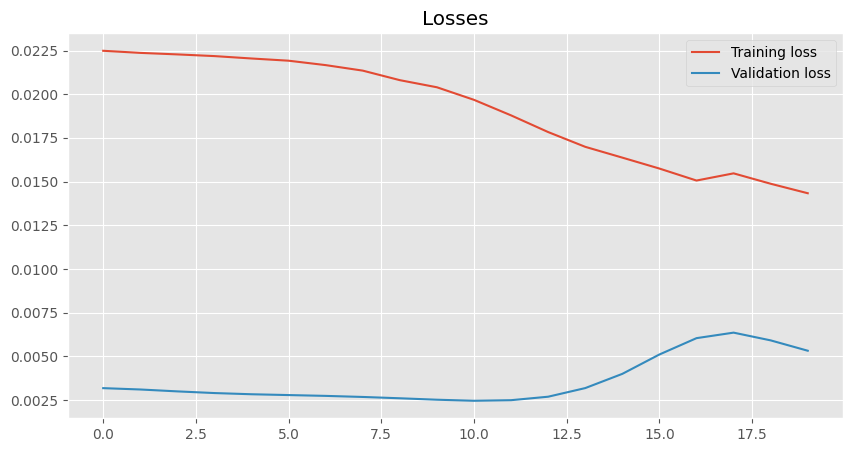

Mean Absolute Error:        51.0323600769043
Root Mean Squared Error:    73.37999743416117
R^2 Score:                  0.5411052703857422


In [22]:
predictions, values = General_Settings("lstm")

df_result = format_predictions(
    predictions,
    values,
    X_test,
    scaler,
    col_name="y"
)

metrics = calculate_metrics(df_result)

La curva de aprendizaje muestra que el modelo LSTM consigue reducir progresivamente la pérdida de entrenamiento a lo largo de las épocas, indicando que la red neuronal aprende patrones presentes en la serie temporal de la gripe. Sin embargo, la pérdida de validación comienza a aumentar ligeramente en las últimas épocas, lo que sugiere un posible inicio de sobreajuste (overfitting).

Las métricas obtenidas pueden considerarse aceptables, aunque muestran que el modelo todavía tiene margen de mejora. El MAE de aproximadamente 51 indica que, en promedio, las predicciones del modelo se desvían unas 51 unidades respecto a los valores reales de la tasa de gripe. Por su parte, el RMSE de alrededor de 73 refleja que existen algunos errores más elevados en determinadas predicciones, ya que esta métrica penaliza más los errores grandes. Además, el coeficiente R² de 0.54 significa que el modelo es capaz de explicar aproximadamente el 54% de la variabilidad de la serie temporal. Aunque este valor muestra que la red neuronal ha aprendido parte importante de los patrones temporales, también indica que todavía existe una cantidad considerable de variabilidad que el modelo no consigue capturar completamente, probablemente debido al comportamiento irregular y a los picos epidémicos característicos de la gripe.

In [23]:
# Define un modelo baseline basado en regresión lineal para comparar el rendimiento del modelo LSTM
def build_baseline_model(df, test_ratio, target_col):
    X, y = feature_label_split(df, target_col)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_ratio,
        shuffle=False
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    result = pd.DataFrame(y_test)
    result["prediction"] = prediction
    result = result.sort_index()

    return result

La regresión lineal se ha seleccionado como modelo de machine learning debido a su simplicidad y facilidad de interpretación, actuando como una baseline de referencia para comparar posteriormente el rendimiento del modelo LSTM. Este modelo permite analizar hasta qué punto las relaciones lineales entre las observaciones pasadas y la tasa de gripe son suficientes para realizar predicciones razonables sobre la serie temporal.

Además, la regresión lineal resulta útil como punto de partida porque requiere un menor coste computacional y proporciona una referencia clara para evaluar si el modelo de deep learning realmente aporta una mejora significativa en la capacidad predictiva. Aunque la serie temporal presenta una fuerte estacionalidad y comportamientos no lineales asociados a los brotes epidémicos, la baseline lineal permite establecer una comparación objetiva frente a arquitecturas más complejas como LSTM

In [24]:
import matplotlib.pyplot as plt
import plotly.graph_objects as go

plt.style.use('ggplot')

# Representación gráfica interactiva de valores reales, predicciones LSTM y baseline lineal
def plot_predictions(df_result, df_baseline):
    data = []

    value = go.Scatter(
        x=df_result.index,
        y=df_result.y,
        mode="lines",
        name="valores reales",
        marker=dict(),
        text=df_result.index,
        line=dict(color="rgba(0,0,0, 0.3)"),
    )
    data.append(value)

    baseline = go.Scatter(
        x=df_baseline.index,
        y=df_baseline.prediction,
        mode="lines",
        line={"dash": "dot"},
        name="regresión lineal",
        marker=dict(),
        text=df_baseline.index,
        opacity=0.8,
    )
    data.append(baseline)

    prediction = go.Scatter(
        x=df_result.index,
        y=df_result.prediction,
        mode="lines",
        line={"dash": "dot"},
        name="predicciones LSTM",
        marker=dict(),
        text=df_result.index,
        opacity=0.8,
    )
    data.append(prediction)

    layout = dict(
        title="Predicciones vs valores reales de la tasa semanal de gripe",
        xaxis=dict(title="Tiempo", ticklen=5, zeroline=False),
        yaxis=dict(title="Tasa de gripe", ticklen=5, zeroline=False),
    )

    fig = go.Figure(data=data, layout=layout)
    fig.show()

## Validación

[1/20] Training loss: 0.0495	 Validation loss: 0.0138
[2/20] Training loss: 0.0435	 Validation loss: 0.0098
[3/20] Training loss: 0.0382	 Validation loss: 0.0065
[4/20] Training loss: 0.0334	 Validation loss: 0.0039
[5/20] Training loss: 0.0292	 Validation loss: 0.0022
[6/20] Training loss: 0.0258	 Validation loss: 0.0015
[7/20] Training loss: 0.0236	 Validation loss: 0.0022
[8/20] Training loss: 0.0230	 Validation loss: 0.0038
[9/20] Training loss: 0.0230	 Validation loss: 0.0052
[10/20] Training loss: 0.0232	 Validation loss: 0.0056


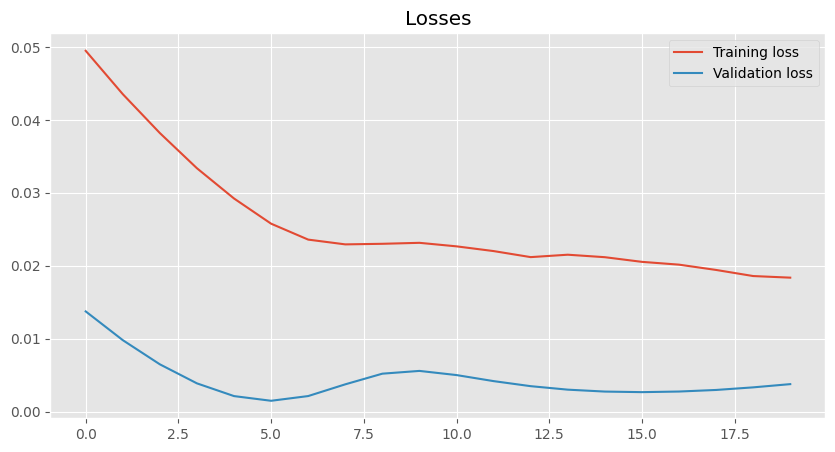

Mean Absolute Error:        70.85202026367188
Root Mean Squared Error:    95.90037962646446
R^2 Score:                  0.2162124514579773
{'mae': 70.85202026367188, 'rmse': 95.90037962646446, 'r2': 0.2162124514579773}
Mean Absolute Error:        35.325992746931696
Root Mean Squared Error:    61.17977827443258
R^2 Score:                  0.6810126242002059
{'mae': 35.325992746931696, 'rmse': 61.17977827443258, 'r2': 0.6810126242002059}


In [25]:
#Evolución de las pérdidas de entrenamiento y validación durante las primeras épocas del modelo LSTM, permitiendo observar el aprendizaje progresivo de la red neuronal
model_name='lstm'
predictions, values=General_Settings(model_name)
df_result=format_predictions(predictions, values, X_test, scaler)
print(calculate_metrics(df_result))
df_baseline = build_baseline_model(df_features, 0.2, 'y')
print(calculate_metrics(df_baseline))
plot_predictions(df_result, df_baseline)

In [29]:
# Métricas del modelo LSTM
metrics_lstm = calculate_metrics(df_result)

# Métricas de la regresión lineal
metrics_baseline = calculate_metrics(df_baseline)

# Tabla comparativa
comparison_table = pd.DataFrame({
    "Modelo": ["LSTM", "Regresión Lineal"],
    "MAE": [metrics_lstm["mae"], metrics_baseline["mae"]],
    "RMSE": [metrics_lstm["rmse"], metrics_baseline["rmse"]],
    "R2": [metrics_lstm["r2"], metrics_baseline["r2"]]
})

comparison_table

Mean Absolute Error:        70.85202026367188
Root Mean Squared Error:    95.90037962646446
R^2 Score:                  0.2162124514579773
Mean Absolute Error:        35.325992746931696
Root Mean Squared Error:    61.17977827443258
R^2 Score:                  0.6810126242002059


,Modelo,MAE,RMSE,R2
0,LSTM,70.852020,95.900380,0.216212
1,Regresión Lineal,35.325993,61.179778,0.681013


La tabla comparativa confirma que la regresión lineal ha obtenido un mejor rendimiento que el modelo LSTM en la predicción de la tasa semanal de gripe. La regresión lineal presenta valores inferiores de MAE y RMSE, lo que indica errores de predicción menores, además de un coeficiente R² considerablemente más alto. En cambio, el modelo LSTM muestra un ajuste más limitado y una menor capacidad explicativa sobre la variabilidad de la serie temporal. Estos resultados sugieren que, para este conjunto de datos concreto y la configuración utilizada, la baseline lineal consigue capturar mejor el comportamiento de la serie que la arquitectura LSTM implementada.